# Axe 1 : la satisfaction au fil de la carrière

Exploration avant de coder la page. La question pour la DRH : **à quel moment de la carrière la satisfaction baisse-t-elle ?**

Les données viennent de `preparer` (population commune, zones, tranches d'expérience et secteur), et la population 2025 de `population_2025`, qui suit `HARMONISATION.md`.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from analyse.chargement import charger
from analyse.population import preparer
from analyse.axe_1 import population_2025, satisfaction_par_experience, comparaison_2025

donnees = preparer(charger(2026))

# zone par défaut du projet : France et pays frontaliers
zone = donnees[donnees["Zone"].isin(["France", "Pays frontaliers"])].copy()
print(len(zone), "personnes en France et pays frontaliers")

3376 personnes en France et pays frontaliers


In [2]:
# on garde ceux qui ont donné leur satisfaction
notes = zone.dropna(subset=["JobSat"])
print(len(notes), "personnes ont donné leur satisfaction")

3356 personnes ont donné leur satisfaction


## 1. La satisfaction selon l'expérience

,moyenne,part_tres_satisfaits,repondants
Tranche_experience,,,
0-1,7.03,0.43,91
2-3,6.80,0.43,246
4-6,6.84,0.40,444
7-10,6.75,0.42,616
11-20,7.03,0.48,1107
21+,7.35,0.54,830


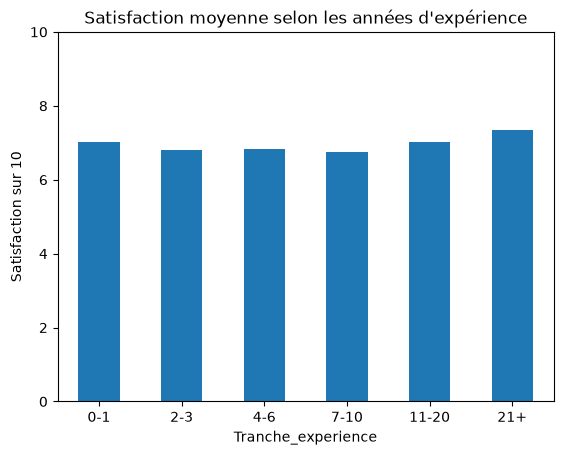

In [3]:
par_experience = satisfaction_par_experience(zone).set_index("Tranche_experience")
display(par_experience.round(2))

par_experience["moyenne"].plot.bar(rot=0, title="Satisfaction moyenne selon les années d'expérience")
plt.ylim(0, 10)
plt.ylabel("Satisfaction sur 10")
plt.show()

**Je remarque :** la satisfaction est de 7,0 la première année, puis descend autour de 6,8 entre 2 et 10 ans d'expérience, avant de remonter à 7,0 puis 7,35 après 20 ans. La part de très satisfaits, 8 ou plus, suit le même chemin : environ 42 % entre 2 et 10 ans, 54 % après 20 ans.

**Je me demande :** l'écart est d'environ un demi-point seulement. Est-ce qu'il est assez net pour en faire le message de la page ?

## 2. En France seule

In [4]:
france = notes[notes["Zone"] == "France"]
display(france.groupby("Tranche_experience", observed=True)["JobSat"].agg(moyenne="mean", repondants="size").round(2))

,moyenne,repondants
Tranche_experience,,
0-1,6.43,23
2-3,6.83,47
4-6,6.60,89
7-10,6.61,120
11-20,7.08,210
21+,7.29,118


**Je remarque :** en France seule, on retrouve le même creux, autour de 6,6 entre 4 et 10 ans. Mais la première année n'a que 23 répondants et 2-3 ans 47 : c'est sous le seuil de 50.

**Je me demande :** il faut sûrement garder la France et les pays frontaliers par défaut, et montrer la France seule seulement quand les effectifs suffisent.

## 3. ESN, éditeurs et autres secteurs

In [5]:
par_secteur = notes.groupby(["Tranche_experience", "Secteur"], observed=True)["JobSat"].agg(["mean", "size"]).unstack()
display(par_secteur.round(2))

mean                                     size  \
Secteur            Autre secteur   ESN Éditeur de logiciels Autre secteur   
Tranche_experience                                                          
0-1                         6.93  7.56                 6.88            59   
2-3                         6.89  6.83                 6.47           168   
4-6                         6.86  6.68                 6.97           281   
7-10                        6.79  6.72                 6.65           381   
11-20                       7.05  6.83                 7.17           673   
21+                         7.29  7.22                 7.69           496   

                                              
Secteur             ESN Éditeur de logiciels  
Tranche_experience                            
0-1                  16                   16  
2-3                  29                   49  
4-6                  93                   70  
7-10                109                  126  
11-20               232                  202  
21+                 171                  163

**Je remarque :** dans les ESN, la satisfaction est de 6,7 entre 4 et 10 ans, un peu en dessous des autres secteurs. Mais avant 4 ans, il n'y a que 16 et 29 personnes en ESN : beaucoup trop peu pour conclure.

**Je me demande :** comment afficher la comparaison ESN sans montrer des chiffres sur 16 personnes ? Il faudra regrouper des tranches, ou masquer celles sous le seuil.

## 4. Comparaison rapide avec 2025

,Tranche_experience,Annee,moyenne,repondants
0,0-1,2025,6.92,106
1,0-1,2026,7.03,91
2,2-3,2025,6.95,401
3,2-3,2026,6.80,246
4,4-6,2025,6.97,688
5,4-6,2026,6.84,444
6,7-10,2025,7.15,992
7,7-10,2026,6.75,616
8,11-20,2025,7.17,1552
9,11-20,2026,7.03,1107


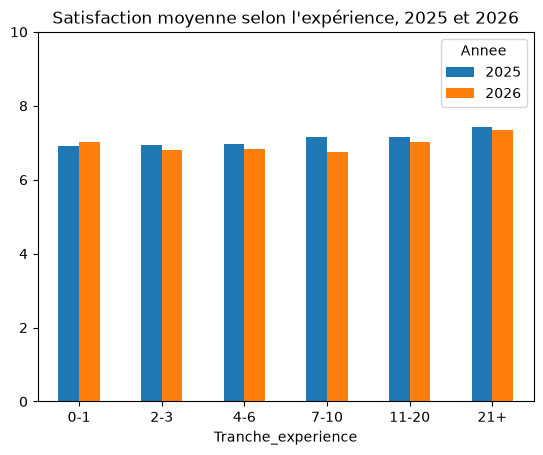

In [6]:
# population 2025 définie comme en 2026, d'après HARMONISATION.md
d2025 = population_2025(charger(2025))
d2025 = d2025[d2025["Zone"].isin(["France", "Pays frontaliers"])]

comparaison = comparaison_2025(zone, d2025)
display(comparaison.round(2))

tableau = comparaison.pivot(index="Tranche_experience", columns="Annee", values="moyenne")
tableau.plot.bar(rot=0, title="Satisfaction moyenne selon l'expérience, 2025 et 2026")
plt.ylim(0, 10)
plt.show()

**Je remarque :** avec la population 2025 de `HARMONISATION.md`, 4 771 personnes, la satisfaction était presque la même de 0 à 10 ans en 2025, entre 6,9 et 7,2. En 2026, elle baisse surtout entre 7 et 10 ans : de 7,15 à 6,75.

**Je me demande :** la correspondance entre les deux années n'est pas parfaite, et les répondants ne sont pas les mêmes. La baisse est-elle un vrai changement, ou un effet de qui a répondu ? Il faut le dire avec prudence sur la page.

## Ce que je retiens pour la page

- Vue principale : la satisfaction selon l'expérience, avec un filtre pour choisir entre la moyenne et la part de 8 ou plus.
- Le creux est réel mais modeste : le titre doit rester prudent, et les effectifs toujours affichés.
- La comparaison ESN : regrouper les tranches ou masquer celles sous 50 répondants.
- La comparaison avec 2025 est la piste la plus intéressante : la baisse entre 7 et 10 ans, à présenter avec prudence.